In [32]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="llama3.2:latest")
print('Model is ready')

Model is ready


In [33]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class ChatState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    user_id: str
    memory: dict

print('State is defined')

State is defined


In [34]:
def assistant_node(state: ChatState)-> dict:
    """One graph node: call the LLM using current messages"""
    response = model.invoke(state["messages"])
    return {"messages": [response]}
print('Nodes are defined')

Nodes are defined


In [ ]:
user_memory_store = {}
def load_memory_node(state: ChatState):
    user_id = state["user_id"]
    memory = user_memory_store.get(user_id,{})

    return {"memory": memory}

In [36]:
from langchain_core.messages import HumanMessage
def assistant_node(state: ChatState):
    memory = state.get("memory", {})
    prompt = f"""User Memory:{memory}
    Answer using memory if useful.
    """
    messages = [HumanMessage(content=prompt)] + state["messages"]
    response = model.invoke(messages)
    return {
        "messages": [response]
    }


In [37]:
def save_memory_node(state: ChatState):
    user_id = state["user_id"]
    last_user_message = ""
    for msg in state["messages"]:
        if isinstance(msg, HumanMessage):
            last_user_message = msg.content
    memory = user_memory_store.get(user_id,{})
    if "my name is" in last_user_message.lower():
        name = last_user_message.split("is")[-1].strip()
        memory["name"] = name
    if "i am a" in last_user_message.lower():
        profession = last_user_message.split("am a")[-1].strip()
        memory["profession"] = profession
    user_memory_store[user_id] = memory
    return {}

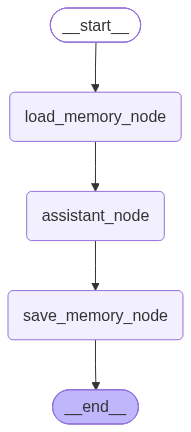

In [38]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(ChatState)
graph_builder.add_node("load_memory_node",load_memory_node)
graph_builder.add_node("assistant_node",assistant_node)
graph_builder.add_node("save_memory_node",save_memory_node)
graph_builder.add_edge(START,"load_memory_node")
graph_builder.add_edge("load_memory_node","assistant_node")
graph_builder.add_edge("assistant_node","save_memory_node")

graph_builder.add_edge("save_memory_node",END)

graph = graph_builder.compile()

graph

In [39]:
from langchain_core.messages import HumanMessage
def chat(user_input,user_id):
    result = graph.invoke({"messages": [HumanMessage(content=user_input)],"user_id": user_id})
    return result["messages"][-1].content

In [40]:
chat("My name is Bapurao", "userA")


"I don't have any prior information about a user named Bapurao in my memory."

In [41]:
chat("I am a AI Developer","userA")

'I have some information about you. You are an AI Developer, which means you design and build artificial intelligence and machine learning models to help businesses, organizations, and individuals solve complex problems and improve their operations. Is that correct?'

In [42]:
chat("What is my name?","userA")

'Your name is Bapurao.'

In [43]:
chat("What is my profession?","userA")

"According to your memory, your profession is 'AI Developer'."

In [44]:
chat("What is my profession?","userB")

"I don't have any information about your profession stored in my user memory. This is the start of our conversation, and I don't retain information about individual users. If you'd like to share your profession with me, I'd be happy to chat with you about it!"